# Lines, Planes, and Hyperplanes
## Visual Exploration for Machine Learning

This notebook complements `README.md`. Instead of repeating all the theory, we'll use Python visualizations to build intuition for:

- A line in 2D
- The effect of slope and intercept
- A linear decision boundary and its normal vector
- A plane in 3D
- The idea of a hyperplane in higher dimensions

**Libraries:** NumPy and Matplotlib.


## 1. A Straight Line in 2D

A line can be represented as:

$$
y = mx + c
$$

- $m$ is the slope.
- $c$ is the y-intercept.

Let's plot a line and highlight the intercept.


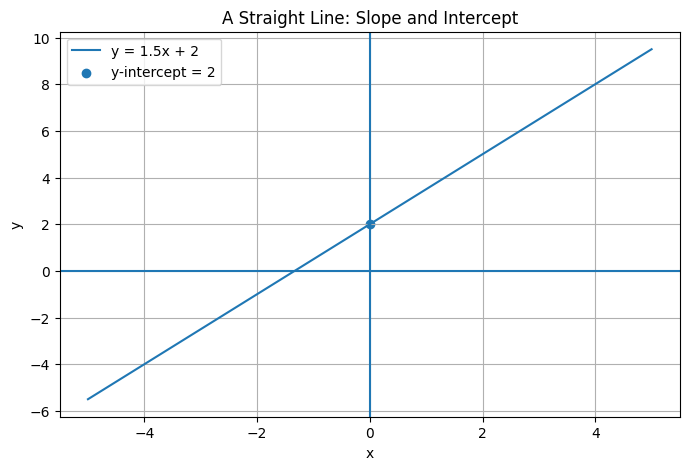

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 200)

m = 1.5
c = 2
y = m * x + c

plt.figure(figsize=(8, 5))
plt.plot(x, y, label=f"y = {m}x + {c}")
plt.scatter([0], [c], label=f"y-intercept = {c}")
plt.axhline(0)
plt.axvline(0)
plt.xlabel("x")
plt.ylabel("y")
plt.title("A Straight Line: Slope and Intercept")
plt.grid(True)
plt.legend()
plt.show()


### Experiment

Change `m` and `c` in the cell above, then run it again.

- Change `m`: the line's steepness and direction change.
- Change `c`: the line shifts up or down.


## 2. Visualizing a Linear Decision Boundary

A line written as

$$
W_1X_1 + W_2X_2 + b = 0
$$

can act as a linear decision boundary in 2D. The line divides the plane into regions where the expression is positive or negative.

For this example, we'll use the boundary $2X_1 + X_2 - 4 = 0$.


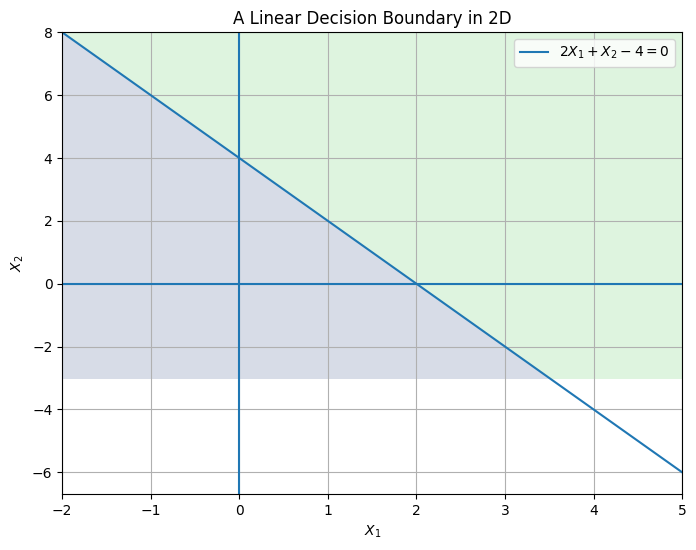

In [2]:
w1 = 2
w2 = 1
b = -4

x1 = np.linspace(-2, 5, 300)
x2 = -(w1 * x1 + b) / w2

X1, X2 = np.meshgrid(
    np.linspace(-2, 5, 250),
    np.linspace(-3, 8, 250)
)
scores = w1 * X1 + w2 * X2 + b

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, scores, levels=[-100, 0, 100], alpha=0.2)
plt.plot(x1, x2, label=r"$2X_1 + X_2 - 4 = 0$")
plt.axhline(0)
plt.axvline(0)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("A Linear Decision Boundary in 2D")
plt.grid(True)
plt.legend()
plt.show()


The boundary is the set of points where the expression equals zero. The shaded regions represent points where the expression is negative or positive.

This is the geometry behind a linear decision boundary; the plot is illustrative and does not train a classifier.


## 3. The Weight Vector Is Normal to the Line

For a boundary $W^T X + b = 0$, the weight vector $W = (W_1, W_2)$ is perpendicular to the line.

We'll plot the line $2X_1 + X_2 - 4 = 0$ and its weight vector, anchored at one point on the line.


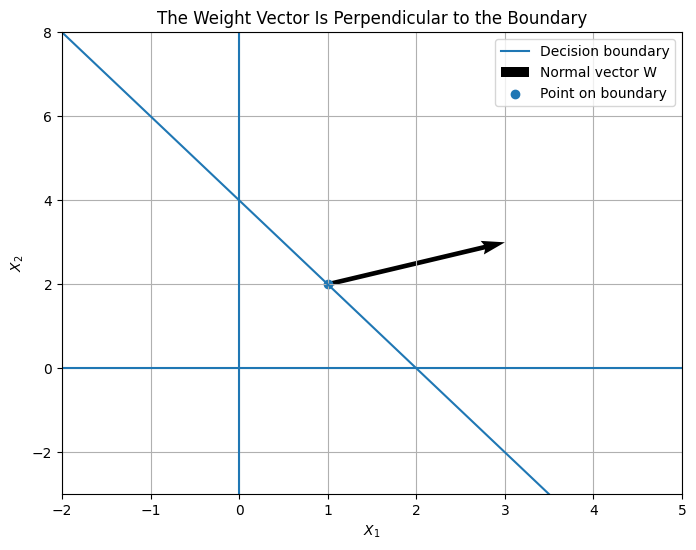

In [3]:
# A point on the line: (1, 2), because 2(1) + 2 - 4 = 0
point = np.array([1.0, 2.0])
W = np.array([w1, w2])

plt.figure(figsize=(8, 6))
plt.plot(x1, x2, label="Decision boundary")
plt.quiver(
    point[0], point[1], W[0], W[1],
    angles="xy", scale_units="xy", scale=1,
    label="Normal vector W"
)
plt.scatter([point[0]], [point[1]], label="Point on boundary")
plt.xlim(-2, 5)
plt.ylim(-3, 8)
plt.axhline(0)
plt.axvline(0)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("The Weight Vector Is Perpendicular to the Boundary")
plt.grid(True)
plt.legend()
plt.show()


The vector $W$ points in the direction of greatest increase of the linear expression $W^T X + b$. It is perpendicular to the boundary.

**Try it:** Change `w1` and `w2` in the earlier cell and rerun this section's code cells. Keep `w2` non-zero for the line equation used here.


## 4. A Plane in 3D

With three features, the equation becomes:

$$
W_1X_1 + W_2X_2 + W_3X_3 + b = 0
$$

We'll visualize one plane:

$$
X_1 + 2X_2 + X_3 - 4 = 0
$$

Rearranging gives $X_3 = 4 - X_1 - 2X_2$.


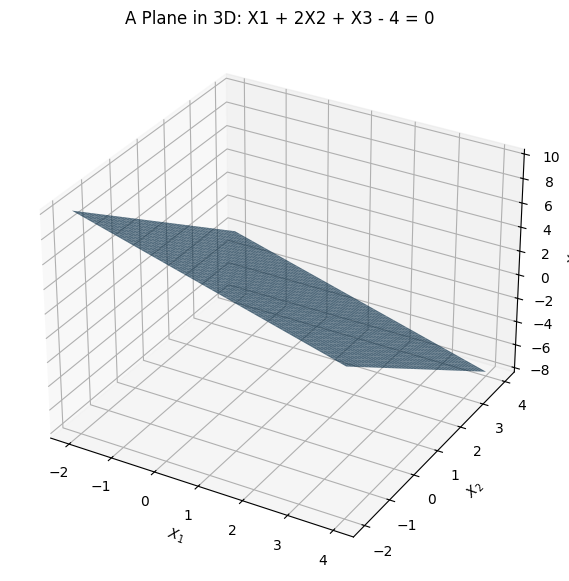

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # Registers 3D projection support

x1_3d = np.linspace(-2, 4, 40)
x2_3d = np.linspace(-2, 4, 40)
X1_3d, X2_3d = np.meshgrid(x1_3d, x2_3d)
X3_3d = 4 - X1_3d - 2 * X2_3d

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X1_3d, X2_3d, X3_3d, alpha=0.7)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_zlabel("$X_3$")
ax.set_title("A Plane in 3D: X1 + 2X2 + X3 - 4 = 0")
plt.show()


The 3D plane is the analogue of a 2D line. In both cases, the weights form the normal vector to the boundary.


## 5. What About a Hyperplane?

A hyperplane in $n$ dimensions has the equation:

$$
W^T X + b = 0
$$

For example, with four features:

$$
W_1X_1 + W_2X_2 + W_3X_3 + W_4X_4 + b = 0
$$

We cannot directly draw four spatial dimensions on a normal 2D screen. The equation still defines a hyperplane, even when we cannot visualize all its dimensions at once.

The general pattern is:

| Number of features | Boundary |
|---:|---|
| 2 | Line |
| 3 | Plane |
| 4 or more | Hyperplane |


## 6. Bias and Passing Through the Origin

The general equation is:

$$
W^T X + b = 0
$$

If the boundary passes through the origin, then $X = 0$ at a point on it, so:

$$
W^T(0) + b = 0 \Rightarrow b = 0
$$

The equation becomes:

$$
W^T X = 0
$$

For a 2D example, compare how changing the bias moves the boundary while keeping the weights fixed.


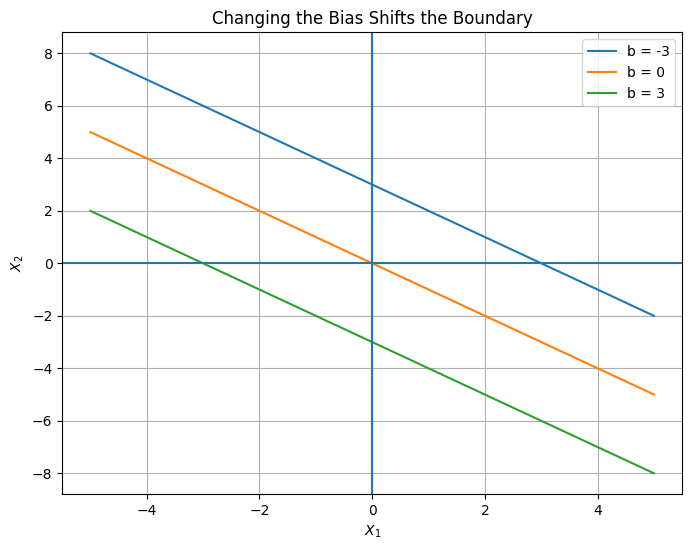

In [5]:
w1_demo = 1
w2_demo = 1
bias_values = [-3, 0, 3]
x_demo = np.linspace(-5, 5, 200)

plt.figure(figsize=(8, 6))
for bias in bias_values:
    y_demo = -(w1_demo * x_demo + bias) / w2_demo
    plt.plot(x_demo, y_demo, label=f"b = {bias}")

plt.axhline(0)
plt.axvline(0)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Changing the Bias Shifts the Boundary")
plt.grid(True)
plt.legend()
plt.show()


## 7. Quick Self-Check

1. What does the slope change in a line?
2. What does the intercept change?
3. In $W^T X + b = 0$, what does $W$ represent geometrically?
4. What geometric object corresponds to three features?
5. What is the equation when a boundary passes through the origin?
6. Why can't we directly plot a full four-dimensional hyperplane in an ordinary 3D plot?

### Answers

1. The line's steepness and direction.
2. The y-intercept; changing the bias shifts the boundary.
3. The normal vector, perpendicular to the boundary.
4. A plane.
5. $W^T X = 0$.
6. A four-dimensional object has one more spatial dimension than a 3D plot can represent directly.
